# 🚀 Practice Day 41

**📅 Date:** **2026-10-20**  
**📁 Category:** **Phase 4 · 캡스톤1(고객 세분화 RFM) (Round 3/3)**

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Segment customers using RFM (Recency, Frequency, Monetary) — the same framework real BAs use to decide who to win back and who to reward
  (RFM(Recency·Frequency·Monetary)으로 고객을 세분화하기 — 실제 BA가 누구를 리텐션하고 누구에게 보상할지 결정할 때 쓰는 방식)
- Design and defend your own segment definitions, then see how much revenue each segment actually accounts for
  (직접 세그먼트 기준을 설계하고, 각 세그먼트가 실제로 매출에서 차지하는 비중까지 확인하기)

---
# 📂 Dataset

**Dataset Name:** Trailhead Supply Co. — Customers & Transactions (2 tables) / Trailhead Supply Co. 아웃도어·캠핑용품 온라인몰 — 고객·구매이력 (2테이블)

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** Two tables: `customers` (55 rows: customer_id, join_date) and `transactions` (276 rows: transaction_id, customer_id → links to customers, purchase_date, amount). Covers one year (2024) of purchase activity at an outdoor/camping gear store. Amounts are in USD. Clean — no missing values or duplicates. Customers vary widely in how often, how recently, and how much they buy, making this a good fit for RFM segmentation.
(`customers`(55명: customer_id, join_date)와 `transactions`(276건: transaction_id, customer_id(customers와 연결), purchase_date, amount) 2개 테이블입니다. 아웃도어·캠핑용품 온라인몰의 2024년 한 해 동안 구매 기록이며, 구매액은 USD입니다. 결측치·중복 없이 깨끗합니다. 고객마다 구매 빈도·최근성·구매액이 크게 다르도록 설계되어 있어 RFM 세분화에 적합합니다. Recency 계산 시 **2025-01-05**를 기준일로 사용하세요.)

## Dataset Preview

In [11]:
# Dataset Preview
import pandas as pd
import numpy as np
from IPython.display import display

np.random.seed(42)
rng = np.random.default_rng(42)

# --- customers and their purchase transactions over 2024 ---
n_customers = 55
customer_ids = [f'C{str(i).zfill(3)}' for i in range(1, n_customers + 1)]

archetypes = rng.choice(
    ['Champion', 'Loyal', 'AtRisk', 'New', 'Lost'],
    size=n_customers,
    p=[0.15, 0.23, 0.19, 0.17, 0.26]
)

year_start = pd.to_datetime('2024-01-01')

rows = []
tx_counter = 1
for cid, arche in zip(customer_ids, archetypes):
    if arche == 'Champion':
        n_tx = rng.integers(8, 15)
        days = sorted(rng.choice(range(0, 365), size=n_tx - 1, replace=False)) + [rng.integers(358, 370)]
        amt_range = (40, 120)  # USD
    elif arche == 'Loyal':
        n_tx = rng.integers(5, 10)
        days = sorted(rng.choice(range(0, 365), size=n_tx, replace=False))
        amt_range = (25, 70)  # USD
    elif arche == 'AtRisk':
        n_tx = rng.integers(6, 11)
        days = sorted(rng.choice(range(0, 190), size=n_tx, replace=False))
        amt_range = (30, 75)  # USD
    elif arche == 'New':
        n_tx = rng.integers(1, 4)
        days = sorted(rng.choice(range(335, 370), size=n_tx, replace=False))
        amt_range = (20, 55)  # USD
    else:  # Lost
        n_tx = rng.integers(1, 3)
        days = sorted(rng.choice(range(0, 140), size=n_tx, replace=False))
        amt_range = (15, 45)  # USD

    for d in days:
        pdate = year_start + pd.Timedelta(days=int(d))
        amt = round(float(rng.uniform(*amt_range)), 1)  # nearest $0.10
        rows.append({'transaction_id': f'T{str(tx_counter).zfill(4)}', 'customer_id': cid,
                     'purchase_date': pdate, 'amount': amt})
        tx_counter += 1

transactions = pd.DataFrame(rows).sort_values('purchase_date').reset_index(drop=True)

customers = pd.DataFrame({
    'customer_id': customer_ids,
    'join_date': [year_start - pd.Timedelta(days=int(rng.integers(30, 900))) for _ in customer_ids]
})

print("Customers:")
display(customers.head())
print("\nTransactions:")
display(transactions.head())


Customers:


,customer_id,join_date
0,C001,2022-02-08
1,C002,2023-03-30
2,C003,2021-08-17
3,C004,2022-06-08
4,C005,2022-01-21



Transactions:


,transaction_id,customer_id,purchase_date,amount
0,T0090,C019,2024-01-01,32.9
1,T0076,C018,2024-01-05,114.2
2,T0195,C039,2024-01-06,52.7
3,T0055,C015,2024-01-07,41.5
4,T0002,C002,2024-01-07,54.9


## Dataset Information

In [12]:
# Dataset Information
print("Customers:", customers.shape)
customers.info()
print("\nTransactions:", transactions.shape)
transactions.info()

print("\n--- Describe: Customers ---")
display(customers.describe(include='all'))
print("\n--- Describe: Transactions ---")
display(transactions.describe(include='all'))


Customers: (55, 2)
<class 'pandas.DataFrame'>
RangeIndex: 55 entries, 0 to 54
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   customer_id  55 non-null     str           
 1   join_date    55 non-null     datetime64[us]
dtypes: datetime64[us](1), str(1)
memory usage: 1012.0 bytes

Transactions: (276, 4)
<class 'pandas.DataFrame'>
RangeIndex: 276 entries, 0 to 275
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   transaction_id  276 non-null    str           
 1   customer_id     276 non-null    str           
 2   purchase_date   276 non-null    datetime64[us]
 3   amount          276 non-null    float64       
dtypes: datetime64[us](1), float64(1), str(2)
memory usage: 8.8 KB

--- Describe: Customers ---


,customer_id,join_date
count,55,55
unique,55,NaN
top,C001,NaN
freq,1,NaN
mean,NaN,2022-08-04 03:29:27.272727
min,NaN,2021-07-28 00:00:00
25%,NaN,2021-12-31 12:00:00
50%,NaN,2022-08-06 00:00:00
75%,NaN,2023-03-22 12:00:00
max,NaN,2023-11-28 00:00:00



--- Describe: Transactions ---


,transaction_id,customer_id,purchase_date,amount
count,276,276,276,276.000000
unique,276,55,NaN,NaN
top,T0090,C018,NaN,NaN
freq,1,14,NaN,NaN
mean,NaN,NaN,2024-06-11 12:41:44.347826,53.891667
min,NaN,NaN,2024-01-01 00:00:00,15.200000
25%,NaN,NaN,2024-02-28 18:00:00,38.750000
50%,NaN,NaN,2024-05-14 12:00:00,51.500000
75%,NaN,NaN,2024-09-22 06:00:00,66.125000
max,NaN,NaN,2025-01-04 00:00:00,117.000000


---
# ❓ Business Questions

1. **(Analysis)** For each customer, what are their Recency (days since last purchase), Frequency (number of transactions), and Monetary (total amount spent) values?
   (고객별 Recency·Frequency·Monetary 값은 각각 얼마인가?)
2. **(Analysis)** Using those RFM values, how would you classify customers into segments (e.g., Champions, Loyal, At Risk, Lost), and how many customers fall into each?
   (RFM 값을 기준으로 고객을 세그먼트로 분류하면(예: Champions/Loyal/At Risk/Lost), 각 세그먼트에는 몇 명이 속하는가?)
3. **(Analysis)** What share of total revenue does each segment account for?
   (각 세그먼트는 전체 매출의 몇 %를 차지하는가?)
4. **(Visualization)** Compare the number of customers across segments.
   (세그먼트별 고객 수를 비교하면?)
5. **(Visualization)** Show each segment's share of total revenue.
   (세그먼트별 매출 비중을 보면?)

---
# 🛠 Skills Used

- [x] Pandas — `.merge`, `.groupby`, `.agg`, `pd.qcut`, `.value_counts`
  (병합, 고객별 RFM 집계, 사분위 점수, 세그먼트 인원)
- [x] NumPy — `np.select`
  (세그먼트 규칙 적용)
- [x] Seaborn — `sns.barplot`
  (세그먼트별 고객 수 막대그래프)
- [x] Matplotlib — `ax.pie`
  (세그먼트별 매출 비중 파이차트)  

---
# 🔍 Data Cleaning Check

- [x] Missing — 0 in `transactions` and 0 in `customers`
  (두 테이블 모두 결측 없음)
- [x] Duplicate — 0 in `transactions` and 0 in `customers`
  (두 테이블 모두 중복 없음)
- [x] Wrong Data Types — `purchase_date` and `join_date` are `datetime64`, `amount` is `float64`
  (날짜는 datetime, 금액은 float)
- [ ] Rename — not needed
  (컬럼명 변경 필요 없음)
- [ ] Drop — not needed
  (삭제할 열 없음)  


In [13]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("===== transactions =====")
print("Missing values")
print(transactions.isnull().sum())
print("\nDuplicate rows:", transactions.duplicated().sum())
print("\nDtypes")
print(transactions.dtypes)
print("\nColumn names")
print(transactions.columns.tolist())
obj_cols = transactions.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(transactions[obj_cols].nunique())
print()

print("===== customers =====")
print("Missing values")
print(customers.isnull().sum())
print("\nDuplicate rows:", customers.duplicated().sum())
print("\nDtypes")
print(customers.dtypes)
print("\nColumn names")
print(customers.columns.tolist())
obj_cols = customers.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(customers[obj_cols].nunique())
print()


===== transactions =====
Missing values
transaction_id    0
customer_id       0
purchase_date     0
amount            0
dtype: int64

Duplicate rows: 0

Dtypes
transaction_id               str
customer_id                  str
purchase_date     datetime64[us]
amount                   float64
dtype: object

Column names
['transaction_id', 'customer_id', 'purchase_date', 'amount']

Text columns — unique counts
transaction_id    276
customer_id        55
dtype: int64

===== customers =====
Missing values
customer_id    0
join_date      0
dtype: int64

Duplicate rows: 0

Dtypes
customer_id               str
join_date      datetime64[us]
dtype: object

Column names
['customer_id', 'join_date']

Text columns — unique counts
customer_id    55
dtype: int64



---
# 📊 Analysis

## Question 1

**Question:** For each customer, what are their Recency, Frequency, and Monetary values? (고객별 R/F/M 값은?)

**Result:** The most recent customer (C005) has Recency **1** day, Frequency **10**, Monetary **$791.4**. The least recent (C019) has Recency **370** days, Frequency **1**, Monetary **$32.9**. C018 shows Frequency **14** and Monetary **$1,105.8**.  
(가장 최근 고객 C005는 Recency 1일, Frequency 10건, Monetary $791.4. 가장 오래된 C019는 Recency 370일, Frequency 1건, Monetary $32.9. C018은 Frequency 14건, Monetary $1,105.8)  

**Insight:** Recency spans **1** to **370** days. Recent high-activity rows like C005 and C018 sit far from C019, who last bought **370** days ago and only once.  
(Recency는 1~370일. C005·C018처럼 최근에 자주 산 고객과, 370일 전에 한 번만 산 C019 사이가 큼)  

In [14]:
# Question 1: compute Recency / Frequency / Monetary per customer
# Direction: group transactions by customer_id; Recency = days between 2025-01-05 and each
# customer's most recent purchase_date; Frequency = transaction count; Monetary = amount sum

merged_df = pd.merge(transactions, customers, on='customer_id', how='left')

REFERENCE_DATE = pd.to_datetime('2025-01-05')

user_behavior = merged_df.groupby('customer_id').agg(
    recency=('purchase_date', lambda x: (REFERENCE_DATE - x.max()).days),
    frequency=('transaction_id', 'nunique'),
    monetary=('amount', 'sum')
).reset_index().sort_values('recency')

user_behavior

,customer_id,recency,frequency,monetary
4,C005,1,10,791.4
42,C043,2,2,68.2
3,C004,4,3,130.2
19,C020,4,3,91.9
8,C009,4,8,586.4
27,C028,5,11,756.7
48,C049,5,3,89.9
54,C055,6,2,96.8
35,C036,7,6,274.9
17,C018,7,14,1105.8


## Question 2

**Question:** Using those RFM values, how would you classify customers into segments, and how many fall into each? (RFM 기준 세그먼트 분류와 세그먼트별 인원은?)

**Result:** Lost **18**, New **14**, At Risk **9**, Champions **8**, Loyal **6**. The five counts add to **55**.  
(Lost 18명, New 14명, At Risk 9명, Champions 8명, Loyal 6명. 다섯 더하면 55명)  

**Insight:** Lost is the largest segment and Loyal is the smallest. Lost has **12** more customers than Loyal.  
(Lost가 가장 크고 Loyal이 가장 작음. Lost가 Loyal보다 12명 많음)  

In [15]:
# Question 2: define your own segment rule from R/F/M and classify each customer
# thresholds on Recency/Frequency/Monetary to define segments like Champions/Loyal/At Risk/Lost

user_behavior['R'] = pd.qcut(user_behavior['recency'], q=4, labels=[4,3,2,1]).astype(int)
user_behavior['F'] = pd.qcut(user_behavior['frequency'], q=4, labels=[1,2,3,4]).astype(int)
user_behavior['M'] = pd.qcut(user_behavior['monetary'], q=4, labels=[1,2,3,4]).astype(int)

display(user_behavior.head(5))

conditions = [
    (user_behavior['R'] == 4) & (user_behavior['F'] > 2),  # Champions: very recent, frequent
    (user_behavior['R'] == 3) & (user_behavior['F'] > 2),  # Loyal: fairly recent, frequent
    (user_behavior['R'] < 3) & (user_behavior['F'] > 2),   # At Risk: used to buy often, gone quiet
    (user_behavior['R'] > 2) & (user_behavior['F'] < 3),   # New: recent, few orders
    (user_behavior['R'] < 3) & (user_behavior['F'] < 3),   # Lost: not recent, few orders
]
names = ['Champions', 'Loyal', 'At Risk', 'New', 'Lost']

user_behavior['segment'] = np.select(conditions, names, default='Unknown')

segment_counts = user_behavior['segment'].value_counts()
segment_counts

,customer_id,recency,frequency,monetary,R,F,M
4,C005,1,10,791.4,4,4,4
42,C043,2,2,68.2,4,1,2
3,C004,4,3,130.2,4,2,2
19,C020,4,3,91.9,4,2,2
8,C009,4,8,586.4,4,3,4


segment
Lost         18
New          14
At Risk       9
Champions     8
Loyal         6
Name: count, dtype: int64

## Question 3

**Question:** What share of total revenue does each segment account for? (세그먼트별 매출 비중은?)

**Result:** Champions **39.4%**, At Risk **26.8%**, Loyal **14.6%**, New **13.6%**, Lost **5.6%**.  
(Champions 39.4%, At Risk 26.8%, Loyal 14.6%, New 13.6%, Lost 5.6%)  

**Insight:** Champions plus At Risk is **66.2%** of revenue. Lost is only **5.6%**, even though it had the most customers in Question 2.  
(Champions와 At Risk를 더하면 매출의 66.2%. Lost는 Question 2에서 인원이 가장 많았지만 매출은 5.6%뿐)  

In [16]:
# Question 3: total revenue share by segment
# Direction: group your RFM+segment table by segment and sum Monetary, then convert to % of total

revenue_share_by_segment = (user_behavior.groupby('segment')['monetary'].sum() / user_behavior['monetary'].sum() * 100).sort_values(ascending=False)
revenue_share_by_segment

segment
Champions    39.375828
At Risk      26.817757
Loyal        14.562898
New          13.629060
Lost          5.614457
Name: monetary, dtype: float64

---
# 📈 Visualization

**Chart 1:** Bar chart — customer count by segment (막대그래프: 세그먼트별 고객 수)

*Interpretation:* Lost is the tallest bar at **18**, then New at **14**. Loyal is the shortest at **6**.  
(Lost 막대가 18명으로 가장 높고, 다음은 New 14명. Loyal이 6명으로 가장 짧음)  

---

**Chart 2:** Pie chart (or bar chart) — revenue share by segment (파이차트 또는 막대그래프: 세그먼트별 매출 비중)

*Interpretation:* Champions is the largest slice at **39.4%**. Lost is the smallest at **5.6%**.  
(Champions가 39.4%로 가장 큰 조각. Lost는 5.6%로 가장 작음)  

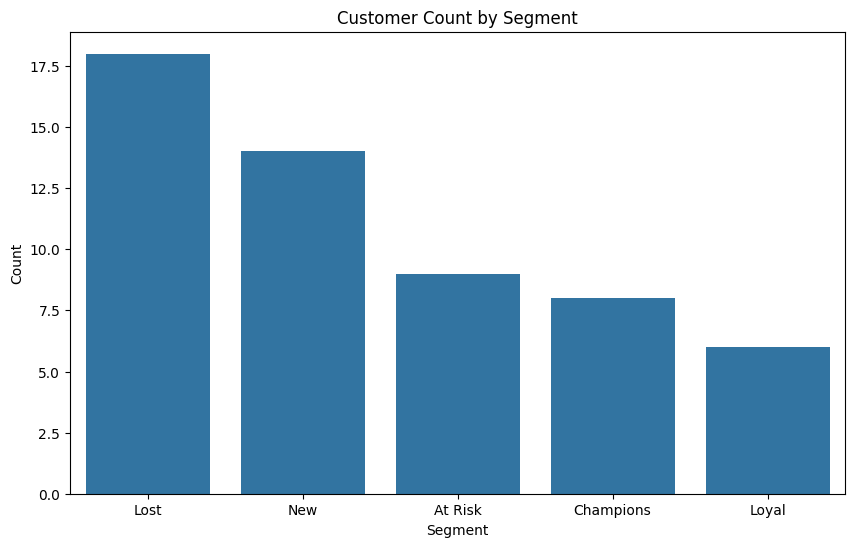

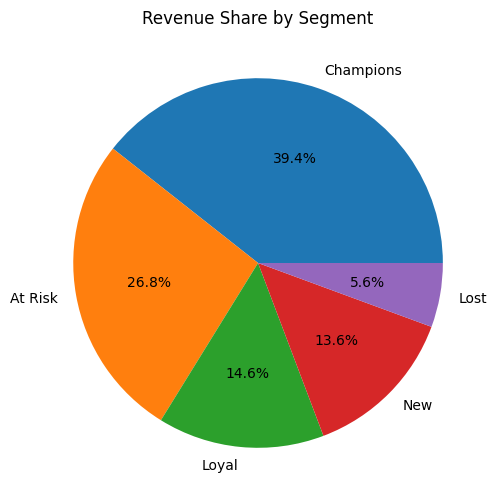

In [17]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: customer count by segment (bar)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=segment_counts.index, y=segment_counts.values, ax=ax)
ax.set_title('Customer Count by Segment')
ax.set_xlabel('Segment')
ax.set_ylabel('Count')
plt.show()

# Chart 2: revenue share by segment (pie or bar)
fig, ax = plt.subplots(figsize=(10, 6))
ax.pie(x=revenue_share_by_segment.values, labels=revenue_share_by_segment.index, autopct='%1.1f%%')
ax.set_title('Revenue Share by Segment')
plt.show()

---
# 💼 Business Insights
*What did I discover?*

- Champions is **8** customers but **39.4%** of revenue.  
  (Champions는 8명인데 매출의 39.4%)
- Lost is the largest group by headcount (**18**) but the smallest by revenue (**5.6%**).  
  (Lost는 인원으로는 가장 큰 그룹(18명)이지만 매출로는 가장 작음(5.6%))
- Champions plus At Risk is **66.2%** of revenue, so those two segments carry most of the money.  
  (Champions와 At Risk를 더하면 매출의 66.2%. 이 두 세그먼트가 매출의 대부분을 담당)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Protect Champions first — **8** customers already account for **39.4%** of revenue.  
   (Champions를 먼저 지키기. 8명이 이미 매출의 39.4%)
2. Do not size a win-back campaign by headcount alone. Lost has **18** customers but only **5.6%** of revenue.  
   (인원만 보고 리텐션 캠페인 규모를 정하지 않기. Lost는 18명이지만 매출은 5.6%)
3. Watch At Risk next. Their revenue share is **26.8%**, second only to Champions.  
   (그다음 At Risk를 보기. 매출 비중 26.8%로 Champions 다음)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- Question 2 was blank until a hint. The missing first step was scoring Recency / Frequency / Monetary before naming segments.  
  (Question 2가 힌트 전까지 비어 있었음. 세그먼트 이름을 붙이기 전에 Recency·Frequency·Monetary 점수를 먼저 매기는 단계가 빠져 있었음)  

---
# ✅ What I Learned
*Today's biggest lesson*

- `pd.qcut` turns Recency / Frequency / Monetary into 1–4 scores. Lower Recency gets the high R score.  
  (pd.qcut으로 Recency·Frequency·Monetary를 1~4점 점수로 바꿈. Recency가 낮을수록 R 점수는 높음)
- `np.select` applies the segment rules in order, so every customer gets one name and the five counts add to **55**.  
  (np.select가 규칙을 순서대로 적용해서 고객마다 이름이 하나 붙고, 다섯 인원을 더하면 55명)
- Headcount order and revenue order can go opposite ways. Lost leads the count at **18** and trails revenue at **5.6%**.  
  (인원 순서와 매출 순서는 반대로 갈 수 있음. Lost는 인원 18명으로 1위, 매출 5.6%로 꼴찌)  

---
# 🧠 Reflection

**What was difficult?**  
Starting Question 2 — turning the RFM table into named segments.  
(Question 2를 시작하는 것. RFM 표를 세그먼트 이름으로 바꾸는 것)

**Why?**  
The question asks for my own rule, so there is no single cutoff to copy.  
(내 규칙을 정하라는 질문이라, 그대로 베낄 컷오프가 하나 있지 않음)

**How did I solve it?**  
Scored R/F/M with `pd.qcut`, then used `np.select` on R and F to name Champions, Loyal, At Risk, New, and Lost.  
(pd.qcut으로 R/F/M 점수를 매긴 뒤, R과 F에 np.select를 써서 Champions·Loyal·At Risk·New·Lost 이름을 붙임)

**What would I do differently next time?**  
Pick the scoring step first, then write the five rules, instead of waiting for the full cell.  
(셀 전체를 기다리지 말고, 점수화부터 정한 다음 규칙 다섯 개를 쓰기)  


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
Computing RFM, scoring with qcut, and reading headcount vs revenue share are clear.  
(RFM 계산, qcut 점수화, 인원 vs 매출 비중 읽기는 이해함)  

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★☆☆☆☆☆  
The questions match earlier RFM days. The new part was writing the segment rule without looking it up.  
(질문은 이전 RFM 날과 같음. 새로웠던 부분은 세그먼트 규칙을 찾아보지 않고 쓰는 것)  

---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 42 — Capstone 2: churn analysis (Round 3/3)  
  (캡스톤 2 — 구독 이탈 분석)  